Risk

# Setup

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Uncomment and run the code to import the libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# Set plotting style
sns.set(style="whitegrid")

# Value at Risk

## Basic Idea

<mark>Q: What is Value-at-Risk?</mark>

* **Value-at-Risk (VaR):** The loss over a target horizon that won’t be exceeded with a given level of confidence.

* For example, suppose we have the following simulated data, which consists of daily P/L for one year:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set NumPy's random seed to `42` with `np.random.seed()`.

In [2]:
np.random.seed(42)

<mark>Q: How to simulate a series of profits and losses drawn from a normal distribution?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw `365` values — one year of daily profit and loss — from a normal distribution with mean `0` and standard deviation `10`, using `np.random.normal()`. Store them in `PL_simulated`.

In [3]:
PL_simulated = np.random.normal(0, 10, 365)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first `10` values of `PL_simulated`.

In [4]:
PL_simulated[:10]

array([ 4.96714153, -1.38264301,  6.47688538, 15.23029856, -2.34153375,
       -2.34136957, 15.79212816,  7.67434729, -4.69474386,  5.42560044])

* What is the VaR for this set of data?

## The Histogram

<mark>Q: How to read the VaR off the distribution of profit and loss?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Uncomment and run the code below, which shows the histogram of `PL_simulated`.

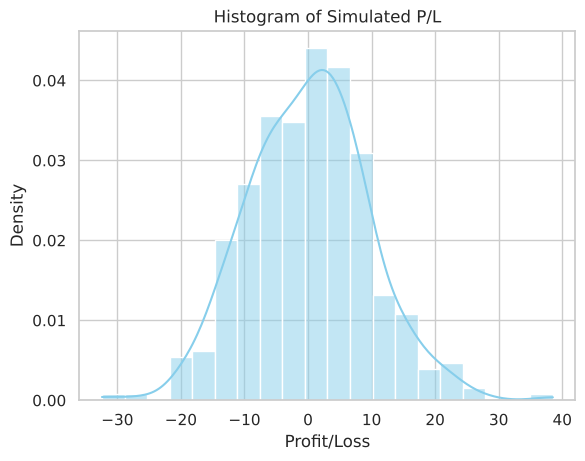

In [5]:
sns.histplot(PL_simulated, kde=True, bins=20, stat="density", color="skyblue")
plt.title("Histogram of Simulated P/L")
plt.xlabel("Profit/Loss")
plt.show()

## 5% one-day VaR

<mark>Q: How to calculate the 5% one-day VaR from a series of profits and losses?</mark>

* 5% one-day VaR is a daily loss such that probability of getting a worse loss is 5%.
* This just corresponds to the 5% quantile.

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `np.quantile()` to get the `0.05` quantile of `PL_simulated`, store it in `quantile_5_percent`, and print it with an f-string labelled `5% Quantile:`.

In [6]:
quantile_5_percent = np.quantile(PL_simulated, 0.05)
print(f"5% Quantile: {quantile_5_percent}")

5% Quantile: -14.456399034337473


* And it is convention to report VaR as a positive number:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Flip the sign of `quantile_5_percent` into `VaR_5_percent`, so the VaR is reported as a positive number, and print it labelled `5% VaR:`.

In [7]:
VaR_5_percent = -quantile_5_percent
print(f"5% VaR: {VaR_5_percent}")

5% VaR: 14.456399034337473


## 1% one-day VaR



* 1% VaR is a daily loss such that probability getting a worse loss is 1%.
* This just corresponds to the 1% quantile:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Do the same at the 1% level: take the `0.01` quantile of `PL_simulated` into `quantile_1_percent` and print it labelled `1% Quantile:`.

In [8]:
quantile_1_percent = np.quantile(PL_simulated, 0.01)
print(f"1% Quantile: {quantile_1_percent}")

1% Quantile: -19.69713688539378


* And it is convention to report VaR as a positive number:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Flip its sign into `VaR_1_percent` and print it labelled `1% VaR:`.

In [9]:
VaR_1_percent = -quantile_1_percent
print(f"1% VaR: {VaR_1_percent}")

1% VaR: 19.69713688539378


## VaR Given Realized Returns

<mark>Q: How to calculate the VaR when we are given a series of realized returns?</mark>



* Very often we are given a series of realized returns.
  * How can we calculate VaR in this case?
* Let's use some real-world data. Say we have invested in a mutual fund.
  * We will use Fidelity Magellan (FMAGX) fund as example.



## Mutual Fund Data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$  Uncomment and run the code below to download the price data for the selected mutual fund from Yahoo Finance.

In [10]:
symbol = "FMAGX"
fund_data = yf.download(symbol, start="1900-01-01", auto_adjust=True, multi_level_index=False, progress=False)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `fund_data` with `.head()`.

In [11]:
fund_data.head()

,Close,High,Low,Open,Volume
Date,,,,,
1980-01-02,0.078753,0.078753,0.078753,0.078753,0
1980-01-03,0.078703,0.078703,0.078703,0.078703,0
1980-01-04,0.080892,0.080892,0.080892,0.080892,0
1980-01-07,0.081787,0.081787,0.081787,0.081787,0
1980-01-08,0.082782,0.082782,0.082782,0.082782,0


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the `'Close'` column of `fund_data`.

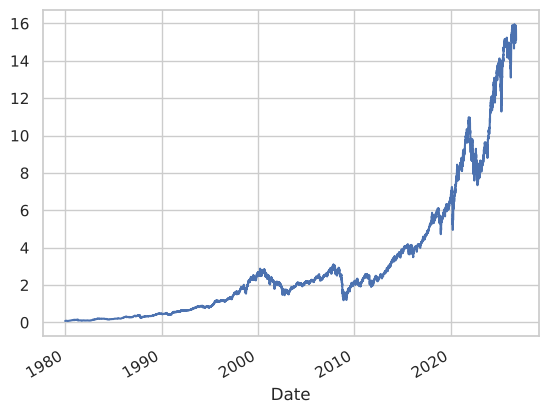

In [12]:
fund_data['Close'].plot()
plt.show()

## Mutual fund returns



* Next we calculate the *daily* return (in percentage):

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the daily return in percent: call `.pct_change()` on `fund_data['Close']`, drop the missing first value with `.dropna()`, multiply by `100`, and store the result in `r_p`.

In [13]:
r_p = fund_data['Close'].pct_change().dropna() * 100

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_p`.

In [14]:
r_p.head()

Date
1980-01-03   -0.063198
1980-01-04    2.781306
1980-01-07    1.107035
1980-01-08    1.216529
1980-01-09    0.600963
Name: Close, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ A Series has no column label to rename, so set its `.name` attribute to `'r_p'` and display the first few rows again.

In [15]:
r_p.name = 'r_p'
r_p.head()

Date
1980-01-03   -0.063198
1980-01-04    2.781306
1980-01-07    1.107035
1980-01-08    1.216529
1980-01-09    0.600963
Name: r_p, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Get the summary statistics of `r_p` with `.describe()`.

In [16]:
r_p.describe()

count    11793.000000
mean         0.052487
std          1.244012
min        -32.141692
25%         -0.469482
50%          0.087073
75%          0.627464
max         14.985250
Name: r_p, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_p` with the title `"Daily Returns (%)"`, and label the y axis `"Return (%)"` with `plt.ylabel()`.

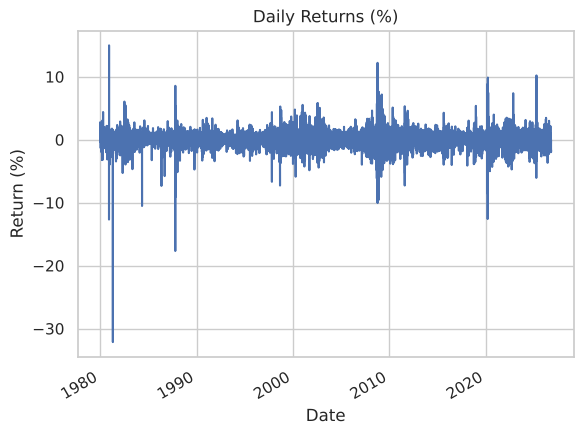

In [17]:
r_p.plot(title="Daily Returns (%)")
plt.ylabel("Return (%)")
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the distribution of `r_p` with `sns.histplot()`.

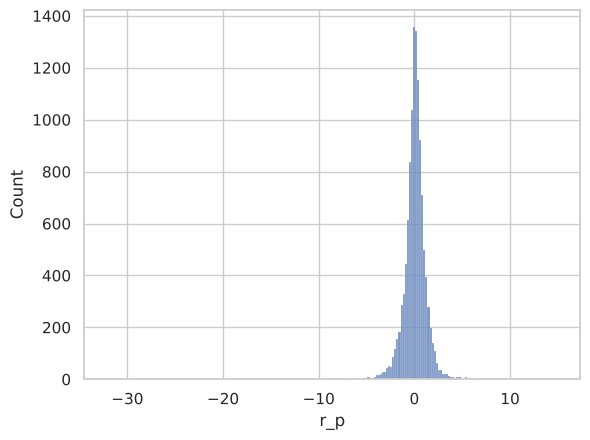

In [18]:
sns.histplot(r_p)
plt.show()

## Two Methods to Calculate VaR

<mark>Q: What is the difference between the parametric and the nonparametric approach to VaR?</mark>



* We will study two methods to calculate the VaR
    1. **The Parametric Approach:** Assume the return follows a certain distribution, say normal distribution.
    2. **The Nonparametric Approach:** Also called historical VaR approach.



## Historical VaR

<mark>Q: How to calculate the historical VaR in percentage terms?</mark>



* We will first find the VaR in percentage terms, say the 5% VaR in percentage terms, so that the chance of getting worse return is 5%.
* The 5% VaR in percentage terms will correspond to the 5% quantile of the returns:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Get the 5% quantile on `r_p`, store it in variable`r_p_quantile_5_percent`.  Print it labelled `5% Quantile:`, formatted to four decimal places and followed by a percent sign, `{...: .4f}%`.

In [19]:
r_p_quantile_5_percent = np.quantile(r_p, 0.05)
print(f"5% Quantile: {r_p_quantile_5_percent: .4f}%")

5% Quantile: -1.7770%


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Flip the sign into `historical_VaR_percentage_terms` and print it labelled `Historical VaR (%):`, again to four decimal places.

In [20]:
historical_VaR_percentage_terms = -r_p_quantile_5_percent
print(f"Historical VaR (%): {historical_VaR_percentage_terms: .4f}%")

Historical VaR (%):  1.7770%


**Interpretation:** In one day, there is 5% chance that the loss will be greater than the calculated percent above.

## From Percentage Terms to Dollar Terms

<mark>Q: How to translate a VaR in percentage terms into dollar terms?</mark>

* We can then easily translate to a VaR in dollar terms.
* Say we initially invested $10 million in the fund.
* Then the one-day 5% VaR in dollar terms as follows:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Store the size of the investment, `10000000` (ten million dollars), in `initial_investment`.

In [21]:
initial_investment = 10000000

<mark>Q: How to print a number with a thousands separator?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert the VaR to dollar terms: multiply `initial_investment` by `historical_VaR_percentage_terms` and divide by `100`, store it in `historical_VaR_dollar_terms`, and print it labelled `Historical VaR ($):` using the format `{...:,.2f}` — a thousands separator and two decimals.

In [22]:
historical_VaR_dollar_terms = initial_investment * historical_VaR_percentage_terms / 100
print(f"Historical VaR ($): {historical_VaR_dollar_terms:,.2f}")

Historical VaR ($): 177,699.64


## The Parametric Approach

<mark>Q: How to calculate the VaR assuming the returns are normally distributed?</mark>

* Let's assum the returns follow a **normal** distribution.
    - The parametric VaR here is also called **normal** VaR.
* A normal distribution is completely characterized by its mean $\mu$ and standard deviation $\sigma$.
* So let's estimate these two parameters first:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Estimate the mean of `r_p` with `.mean()`, store it in `miu`, and print its value.

In [23]:
miu = r_p.mean()
print(miu)

0.05248699538222404


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Estimate the standard deviation of `r_p` with `.std()`, store it in `sig`, and print its value.

In [24]:
sig = r_p.std()
print(sig)

1.244012288371256


## VaR Calculation: Finding Quantile

<mark>Q: How to find the quantile of a standard normal distribution in Python?</mark>

* Given that the return $r_p$ is normally distributed with $\mu$ and $\sigma$, what is the 5% VaR (daily)?
    * This would correspond to the 5% quantile of $r_p$.
* Let's transform (standardize) r_p into z: $$z \equiv \frac{r_p - \mu}{\sigma}$$
    - z is standard normal (mean zero and standard deviation of 1)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ There exists a Percent Point Function in `scipy` to find the quantile for a standard normal random variable. Uncomment and run the following code.

In [25]:
from scipy.stats import norm
z_quantile = norm.ppf(0.05)
print(f"Z Quantile: {z_quantile}")

Z Quantile: -1.6448536269514729


## VaR Calculation



* We then transform this quantile to the quantile for $r_p$.
    - Since $z_{quantile} = \frac{r_{p,quantile} - \mu}{\sigma}$
    - We have: $r_{p,quantile} = \mu + \sigma \times z_{quantile}$

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Transform the standard normal quantile back to the return scale:  `miu + sig * z_quantile`, store it in `r_p_quantile`, and print it labelled `Normal Quantile:` to four decimal places.

In [26]:
r_p_quantile = miu + sig * z_quantile
print(f"Normal Quantile: {r_p_quantile:.4f}")

Normal Quantile: -1.9937


* VaR in percentage terms:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Flip the sign into `normal_VaR_percentage_terms` and print it labelled `Normal VaR (%):` to four decimal places.

In [27]:
normal_VaR_percentage_terms = -r_p_quantile
print(f"Normal VaR (%): {normal_VaR_percentage_terms:.4f}")

Normal VaR (%): 1.9937


* VaR in dollar terms:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert it to dollar terms the same way as before:  `initial_investment` times `normal_VaR_percentage_terms`, divided by `100`, save it into variable `normal_VaR_dollar_terms`, and print it labelled `Normal VaR ($):` with a thousands separator and two decimals.

In [28]:
normal_VaR_dollar_terms = initial_investment * normal_VaR_percentage_terms / 100
print(f"Normal VaR ($): {normal_VaR_dollar_terms:,.2f}")

Normal VaR ($): 199,373.11


## VaR at different horizon

<mark>Q: How to scale the mean and the standard deviation from a daily to an annual horizon?</mark>

* One advantage of the normal VaR approach is that we can easily calculate the VaR at different horizons.

* For example, what is the 5% VaR for one year?

* First we find the mean and sd for the annual horizon:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ The expected return grows linearly with the horizon: multiply `miu` by the `252` trading days in a year into variable `miu_annual`, and print its value.

In [29]:
miu_annual = miu * 252
print(miu_annual)

13.226722836320457


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ The standard deviation grows with the square root of the horizon: multiply `sig` by `np.sqrt(252)` into variable `sig_annual`, and print its value.

In [30]:
sig_annual = sig * np.sqrt(252)
print(sig_annual)

19.748082857632276


## Annual VaR



* Quantile:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Find the annual 5% quantile exactly as you did the daily one:  `miu_annual + sig_annual * z_quantile`, save it into variable `r_p_annual_quantile`, and print it labelled `Annual Quantile:` to four decimal places.

In [31]:
r_p_annual_quantile = miu_annual + sig_annual * z_quantile
print(f"Annual Quantile: {r_p_annual_quantile:.4f}")

Annual Quantile: -19.2560


* VaR in percentage terms:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Flip the sign into `normal_VaR_annual_percentage_terms` and print it labelled `Annual VaR (%):` to four decimal places.

In [32]:
normal_VaR_annual_percentage_terms = -r_p_annual_quantile
print(f"Annual VaR (%): {normal_VaR_annual_percentage_terms:.4f}")

Annual VaR (%): 19.2560


* VaR in dollar terms:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert it to dollar terms into `normal_VaR_annual_dollar_terms` and print it labelled `Annual VaR ($):` with a thousands separator and two decimals.

In [33]:
normal_VaR_annual_dollar_terms = initial_investment * normal_VaR_annual_percentage_terms / 100
print(f"Annual VaR ($): {normal_VaR_annual_dollar_terms:,.2f}")

Annual VaR ($): 1,925,598.29


## Historical VaR versus Parametric VaR



* At the daily horizon:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Uncomment and run the following code, which prints the two daily VaR figures in dollar terms one after the other.

In [34]:
print(f"Historical: ${historical_VaR_dollar_terms: ,.2f}")
print(f"Parametric: ${normal_VaR_dollar_terms: ,.2f}")

Historical: $ 177,699.64
Parametric: $ 199,373.11




## Are returns normally distributed?

<mark>Q: How to compare the actual distribution of returns with a fitted normal distribution?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw the histogram of `r_p` with `sns.histplot()`, then overlay the fitted normal density. Uncomment and run the following code.

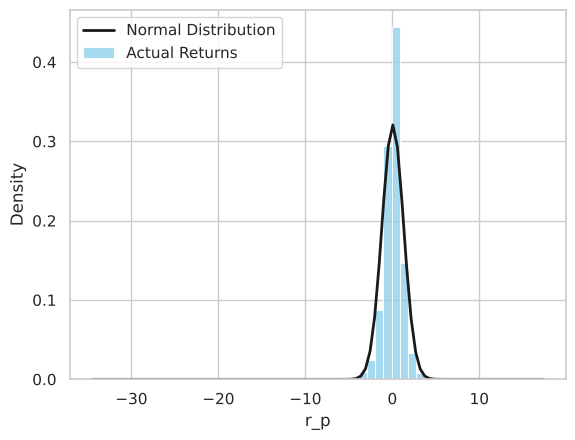

In [35]:
sns.histplot(r_p, kde=False, stat="density", bins=50, color="skyblue", label="Actual Returns")

# Overlay normal distribution curve
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, miu, sig)
plt.plot(x, p, 'k', linewidth=2, label="Normal Distribution")
plt.legend()
plt.show()

## Probability of Observing Extreme Returns

* Let's find the probability of the minimum return observed assuming a normal distribution:

<mark>Q: How to find the probability of an extreme return under the normal assumption?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Find the worst daily return with `.min()` on `r_p`, store it in `r_p_min`, and print it.

In [36]:
r_p_min = r_p.min()
print(r_p_min)

-32.141691882770154


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `norm.cdf()` with `loc=miu` and `scale=sig` to get the probability of a return at or below `r_p_min` under the normal assumption.

In [37]:
norm.cdf(r_p_min, loc=miu, scale=sig)

np.float64(5.69390880788782e-148)

# Expected Shortfall


## VaR Shortcomings

<mark>Q: What are the shortcomings of VaR?</mark>

* VaR does not consider the distribution of returns in the tail.
    - So, two distributions could have the same VaR, but very different tail behavior.
* VaR asks "what is the loss amount, so that I’ll lose more than that (over the given horizon) with, say 5% probability?"
    - But maybe we want to ask: How much might I lose in that 5% scenario?
    - Alternative risk measure to address this issue: **expected shortfall**


## Expected Shortfall (ES)

* ES allows us to answer the question, "if losses exceed VaR, how bad should we expect that loss to be?"
* ES is also called
    - conditional value at risk (CVaR)
    - average value at risk (AVaR)
    - expected tail loss (ETL)

## ES calculation

<mark>Q: How to calculate the expected shortfall?</mark>

* Given the probability, find the VaR, and then ES is equalt to the average of all the losses that are bigger than the VaR.

* In our example, first find the left tail (5% probability).

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Print `r_p_quantile_5_percent` again. This is the cutoff that defines the tail.

In [38]:
print(r_p_quantile_5_percent)

-1.7769963954990309


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Filter `r_p` down to the returns strictly below `r_p_quantile_5_percent`, store them in variable `left_tail`, and display the first few rows with `.head()`.

In [39]:
left_tail = r_p[r_p < r_p_quantile_5_percent]
left_tail.head()

Date
1980-02-14   -1.908400
1980-03-05   -1.814109
1980-03-06   -2.078507
1980-03-17   -3.155333
1980-03-24   -3.191502
Name: r_p, dtype: float64

* Calculate (daily) ES as the average tail loss (in percentage terms):

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Average the tail losses with `.mean()` on `left_tail`, flip the sign into `ES_percentage_terms`, and print it labelled `Expected Shortfall (%):` to four decimal places.

In [40]:
ES_percentage_terms = -left_tail.mean()
print(f"Expected Shortfall (%): {ES_percentage_terms:.4f}")

Expected Shortfall (%): 2.9222


* ES in dollar terms:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert it to dollar terms into `ES_dollar_terms` and print it labelled `Expected Shortfall ($):` with a thousands separator and two decimals.

In [41]:
ES_dollar_terms = initial_investment * ES_percentage_terms / 100
print(f"Expected Shortfall ($): {ES_dollar_terms:,.2f}")

Expected Shortfall ($): 292,222.70


* Compared to VaR:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Print the historical VaR and the expected shortfall side by side, both in dollar terms with a thousands separator and two decimals. Uncomment and run the following code.

In [42]:
print(f"Historical VaR ($): {historical_VaR_dollar_terms:,.2f}")
print(f"Expected Shortfall ($): {ES_dollar_terms:,.2f}")

Historical VaR ($): 177,699.64
Expected Shortfall ($): 292,222.70
